In [3]:
import sys
sys.path.append('..')

import numpy as np
import matplotlib.pyplot as plt
from python.ksg_estimator import mi_knn
import pandas as pd

In [4]:
#dataset size
N = 1000

#generate one random full dataset
x = np.random.rand(N, 1)
y = 2 * x + 3

#compute MI on the full dataset (100%)
#this will be the ceiling/reference line
mi_ceiling = mi_knn(x, y, K=2)

print(f"Ceiling MI (full dataset): {mi_ceiling:.4f} nats")

Ceiling MI (full dataset): 5.4866 nats


In [5]:
ratios = np.arange(0.10, 1.00, 0.05)  #10%, 15%, ..., 95%
n_trials = 100

results = []  #will store (ratio, trial, n_points, mi)

for ratio in ratios:
    for trial in range(n_trials):

        #generate a new dataset for this trial
        x = np.random.rand(N, 1)
        y = 2 * x + 3

        #generate a new random index
        ix = np.random.rand(N) < ratio

        x_sub = x[ix]
        y_sub = y[ix]

        #number of selected points
        n_points = len(x_sub)

        #compute MI
        mi = mi_knn(x_sub, y_sub, K=2)

        #store results
        results.append((ratio, trial, n_points, mi))

print(f"Total runs: {len(results)}")

Total runs: 1800


In [6]:
#convert results to a DataFrame
df = pd.DataFrame(results, columns=["ratio", "trial", "n_points", "mi"])

#round ratio values to avoid floating-point messiness
df["ratio"] = df["ratio"].round(2)

#inspect the first few rows
print(df.head(20))

#check ratios and number of trials
print("\nUnique ratios:")
print(df["ratio"].unique())

print("\nTrials per ratio:")
print(df.groupby("ratio")["trial"].count())

print("\nMI statistics per ratio:")
print(df.groupby("ratio")["mi"].describe().round(4))

print("\nSubsample size statistics per ratio:")
print(df.groupby("ratio")["n_points"].describe().round(2))

    ratio  trial  n_points        mi
0     0.1      0       109  3.307070
1     0.1      1        99  3.094577
2     0.1      2       109  3.307157
3     0.1      3       110  3.257418
4     0.1      4       102  3.148998
5     0.1      5        92  3.101595
6     0.1      6       103  3.163504
7     0.1      7        94  3.079074
8     0.1      8       109  3.222630
9     0.1      9        99  3.138869
10    0.1     10       117  3.325661
11    0.1     11       109  3.306338
12    0.1     12       110  3.261859
13    0.1     13       116  3.282404
14    0.1     14       106  3.219799
15    0.1     15        91  3.147685
16    0.1     16        90  3.143545
17    0.1     17       110  3.247599
18    0.1     18        89  3.095336
19    0.1     19       100  3.191731

Unique ratios:
[0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.75
 0.8  0.85 0.9  0.95]

Trials per ratio:
ratio
0.10    100
0.15    100
0.20    100
0.25    100
0.30    100
0.35    100
0.40    100
0.45 

In [7]:
summary = df.groupby("ratio").agg(mean_mi=("mi", "mean"), std_mi=("mi", "std"), mean_n_points=("n_points", "mean"),std_n_points=("n_points", "std")).reset_index()

print(summary.round(4))

    ratio  mean_mi  std_mi  mean_n_points  std_n_points
0    0.10   3.1939  0.0886         101.24        9.0108
1    0.15   3.5937  0.0774         151.34       10.8537
2    0.20   3.8856  0.0589         201.92       10.8252
3    0.25   4.0989  0.0527         250.15       12.8089
4    0.30   4.2784  0.0466         298.86       13.7091
5    0.35   4.4255  0.0509         347.85       14.5063
6    0.40   4.5574  0.0464         396.33       15.7986
7    0.45   4.6837  0.0397         447.97       14.5952
8    0.50   4.7918  0.0373         499.99       15.9123
9    0.55   4.8880  0.0331         550.76       16.7327
10   0.60   4.9762  0.0294         601.64       14.4065
11   0.65   5.0545  0.0305         649.71       15.2337
12   0.70   5.1215  0.0243         697.82       13.9714
13   0.75   5.1964  0.0223         748.65       12.6374
14   0.80   5.2606  0.0183         797.97       11.8043
15   0.85   5.3216  0.0191         851.48       10.7096
16   0.90   5.3789  0.0163         899.49       

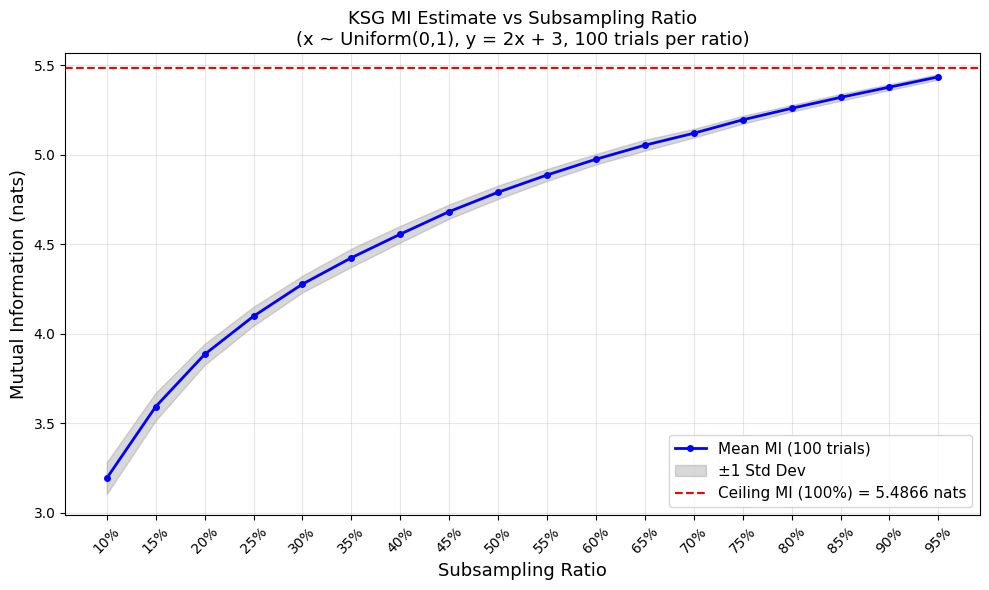

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

#plot mean MI with shaded standard deviation band
ax.plot(summary["ratio"], summary["mean_mi"], color="blue", linewidth=2, marker="o", markersize=4, label="Mean MI (100 trials)")

ax.fill_between(summary["ratio"], summary["mean_mi"] - summary["std_mi"], summary["mean_mi"] + summary["std_mi"], alpha=0.3, color="gray", label="±1 Std Dev")

#ceiling line
ax.axhline(y=mi_ceiling, color="red", linestyle="--", linewidth=1.5, label=f"Ceiling MI (100%) = {mi_ceiling:.4f} nats")

#labels and formatting
ax.set_xlabel("Subsampling Ratio", fontsize=13)
ax.set_ylabel("Mutual Information (nats)", fontsize=13)
ax.set_title("KSG MI Estimate vs Subsampling Ratio\n(x ~ Uniform(0,1), y = 2x + 3, 100 trials per ratio)", fontsize=13)
ax.set_xticks(summary["ratio"])
ax.set_xticklabels([f"{int(r*100)}%" for r in summary["ratio"]], rotation=45)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("subsampling_uniform.png", dpi=150)
plt.show()

------------------

In [9]:
#gaussian ceiling
x_g = np.random.randn(N, 1)
y_g = 2 * x_g + 3
mi_ceiling_g = mi_knn(x_g, y_g, K=2)
print(f"Ceiling MI Gaussian (full dataset): {mi_ceiling_g:.4f} nats")

Ceiling MI Gaussian (full dataset): 5.4963 nats


In [10]:
results_g = []

for ratio in ratios:
    for trial in range(n_trials):
        #generate a new Gaussian dataset for this trial
        x_g = np.random.randn(N, 1)
        y_g = 2 * x_g + 3

        #random boolean index
        ix = np.random.rand(N) < ratio

        x_sub = x_g[ix]
        y_sub = y_g[ix]

        n_points = len(x_sub)
        mi = mi_knn(x_sub, y_sub, K=2)

        results_g.append((ratio, trial, n_points, mi))

print(f"Total runs: {len(results_g)}")

Total runs: 1800


In [11]:
df_g = pd.DataFrame(results_g, columns=["ratio", "trial", "n_points", "mi"])

df_g["ratio"] = df_g["ratio"].round(2)

print(df_g.head(10))

print("\nMI statistics per ratio:")
print(df_g.groupby("ratio")["mi"].describe().round(4))

summary_g = df_g.groupby("ratio").agg(mean_mi=("mi", "mean"), std_mi=("mi", "std"), mean_n_points=("n_points", "mean"), std_n_points=("n_points", "std")).reset_index()

print("\n", summary_g.round(4))

   ratio  trial  n_points        mi
0    0.1      0       103  3.204551
1    0.1      1        97  3.124333
2    0.1      2        84  2.996175
3    0.1      3       115  3.290075
4    0.1      4        98  3.125762
5    0.1      5        85  3.058819
6    0.1      6       106  3.144249
7    0.1      7       123  3.324586
8    0.1      8       105  3.187366
9    0.1      9       107  3.209032

MI statistics per ratio:
       count    mean     std     min     25%     50%     75%     max
ratio                                                               
0.10   100.0  3.1419  0.1110  2.8810  3.0608  3.1451  3.2057  3.3763
0.15   100.0  3.5525  0.0829  3.3479  3.4918  3.5494  3.6124  3.7791
0.20   100.0  3.8569  0.0735  3.6812  3.8095  3.8569  3.9116  4.0086
0.25   100.0  4.0767  0.0636  3.9037  4.0350  4.0739  4.1193  4.2321
0.30   100.0  4.2687  0.0607  4.1192  4.2384  4.2711  4.3029  4.4347
0.35   100.0  4.4287  0.0442  4.2889  4.4001  4.4289  4.4553  4.5460
0.40   100.0  4.5604  0.04

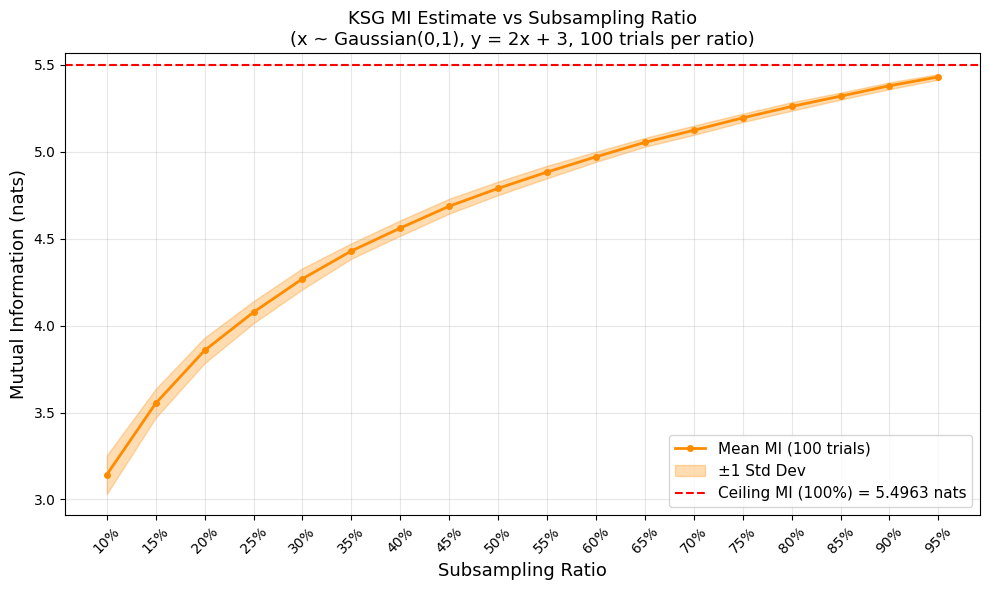

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(summary_g["ratio"], summary_g["mean_mi"], color="darkorange", linewidth=2, marker="o", markersize=4, label="Mean MI (100 trials)")

ax.fill_between(summary_g["ratio"], summary_g["mean_mi"] - summary_g["std_mi"], summary_g["mean_mi"] + summary_g["std_mi"], alpha=0.3, color="darkorange", label="±1 Std Dev")

ax.axhline(y=mi_ceiling_g, color="red", linestyle="--", linewidth=1.5, label=f"Ceiling MI (100%) = {mi_ceiling_g:.4f} nats")

ax.set_xlabel("Subsampling Ratio", fontsize=13)
ax.set_ylabel("Mutual Information (nats)", fontsize=13)
ax.set_title("KSG MI Estimate vs Subsampling Ratio\n(x ~ Gaussian(0,1), y = 2x + 3, 100 trials per ratio)", fontsize=13)
ax.set_xticks(summary_g["ratio"])
ax.set_xticklabels([f"{int(r*100)}%" for r in summary_g["ratio"]], rotation=45)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("subsampling_gaussian.png", dpi=150)
plt.show()

---------------

In [13]:
#exponential ceiling
x_e = np.random.exponential(scale=1.0, size=(N, 1))
y_e = 2 * x_e + 3
mi_ceiling_e = mi_knn(x_e, y_e, K=2)
print(f"Ceiling MI Exponential (full dataset): {mi_ceiling_e:.4f} nats")

Ceiling MI Exponential (full dataset): 5.4708 nats


In [14]:
results_e = []

for ratio in ratios:
    for trial in range(n_trials):
        #generate a new exponential dataset for this trial
        x_e = np.random.exponential(scale=1.0, size=(N, 1))
        y_e = 2 * x_e + 3

        #random boolean index
        ix = np.random.rand(N) < ratio

        x_sub = x_e[ix]
        y_sub = y_e[ix]

        n_points = len(x_sub)
        mi = mi_knn(x_sub, y_sub, K=2)

        results_e.append((ratio, trial, n_points, mi))

print(f"Total runs: {len(results_e)}")

Total runs: 1800


In [15]:
df_e = pd.DataFrame(results_e, columns=["ratio", "trial", "n_points", "mi"])

df_e["ratio"] = df_e["ratio"].round(2)

print(df_e.head(10))

print("\nMI statistics per ratio:")
print(df_e.groupby("ratio")["mi"].describe().round(4))

summary_e = df_e.groupby("ratio").agg(mean_mi=("mi", "mean"), std_mi=("mi", "std"), mean_n_points=("n_points", "mean"), std_n_points=("n_points", "std")).reset_index()

print("\n", summary_e.round(4))

   ratio  trial  n_points        mi
0    0.1      0       116  3.379485
1    0.1      1       108  3.251730
2    0.1      2       115  3.294510
3    0.1      3       103  3.116335
4    0.1      4       108  3.214844
5    0.1      5       108  3.272608
6    0.1      6        97  3.119775
7    0.1      7       113  3.203584
8    0.1      8        85  3.058044
9    0.1      9       124  3.397978

MI statistics per ratio:
       count    mean     std     min     25%     50%     75%     max
ratio                                                               
0.10   100.0  3.1697  0.1098  2.8916  3.0818  3.1793  3.2624  3.3980
0.15   100.0  3.5770  0.0817  3.3401  3.5276  3.5914  3.6363  3.7553
0.20   100.0  3.8707  0.0712  3.7077  3.8218  3.8680  3.9187  4.0510
0.25   100.0  4.0852  0.0613  3.9166  4.0491  4.0894  4.1328  4.1963
0.30   100.0  4.2770  0.0559  4.1044  4.2404  4.2787  4.3160  4.3927
0.35   100.0  4.4281  0.0506  4.3085  4.3931  4.4308  4.4691  4.5224
0.40   100.0  4.5578  0.04

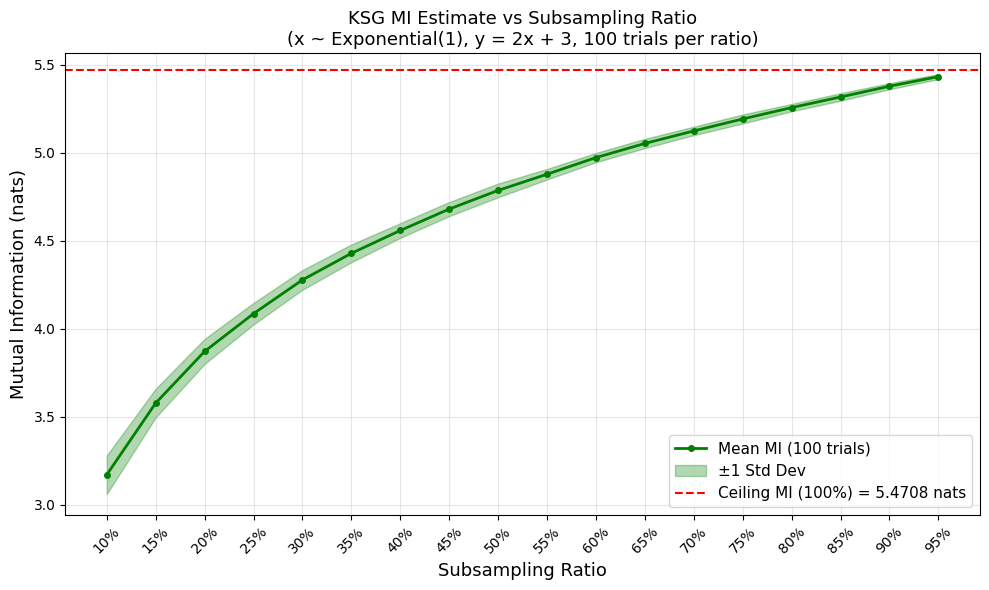

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(summary_e["ratio"], summary_e["mean_mi"], color="green", linewidth=2, marker="o", markersize=4, label="Mean MI (100 trials)")

ax.fill_between(summary_e["ratio"], summary_e["mean_mi"] - summary_e["std_mi"], summary_e["mean_mi"] + summary_e["std_mi"], alpha=0.3, color="green", label="±1 Std Dev")

ax.axhline(y=mi_ceiling_e, color="red", linestyle="--", linewidth=1.5, label=f"Ceiling MI (100%) = {mi_ceiling_e:.4f} nats")

ax.set_xlabel("Subsampling Ratio", fontsize=13)
ax.set_ylabel("Mutual Information (nats)", fontsize=13)
ax.set_title("KSG MI Estimate vs Subsampling Ratio\n(x ~ Exponential(1), y = 2x + 3, 100 trials per ratio)", fontsize=13)
ax.set_xticks(summary_e["ratio"])
ax.set_xticklabels([f"{int(r*100)}%" for r in summary_e["ratio"]], rotation=45)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("subsampling_exponential.png", dpi=150)
plt.show()

---------

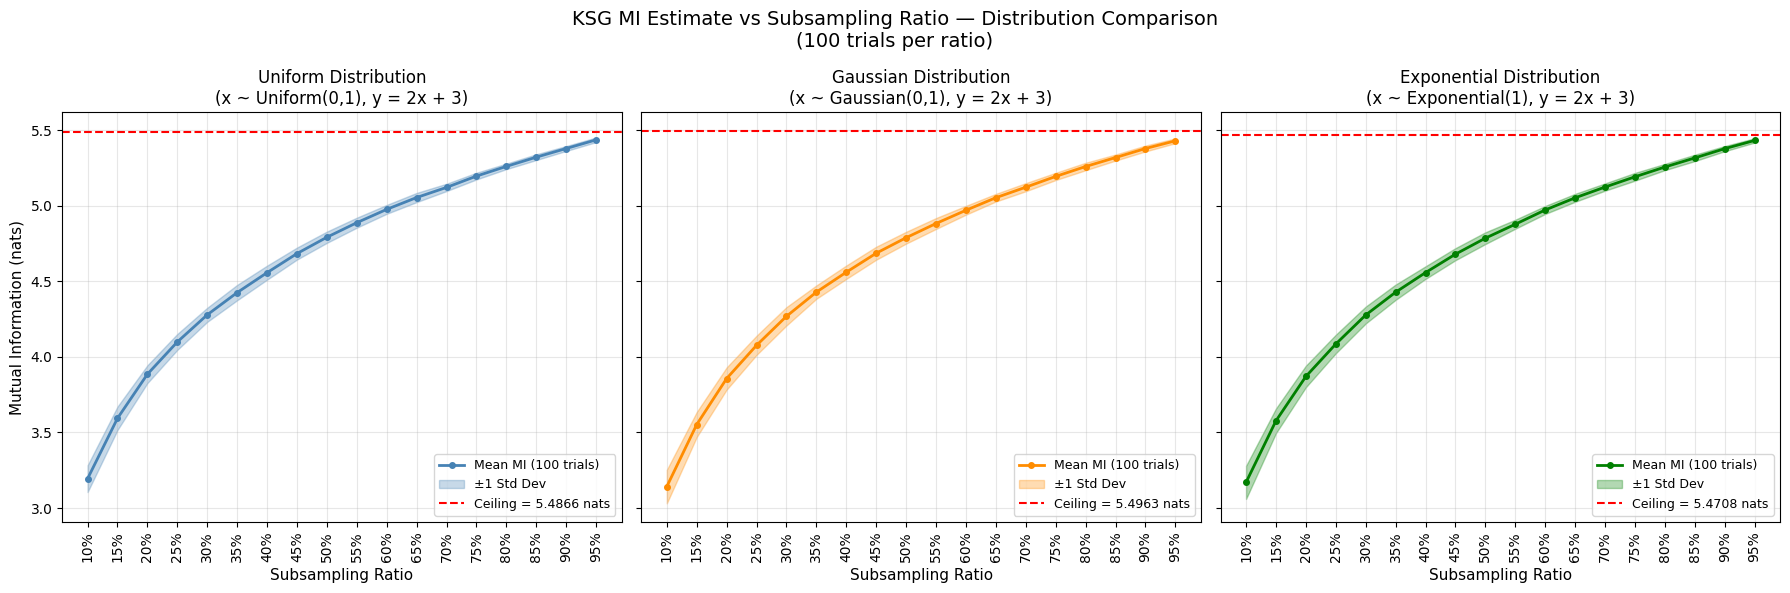

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

datasets = [(summary, mi_ceiling, "steelblue", "Uniform", "x ~ Uniform(0,1)"), (summary_g, mi_ceiling_g, "darkorange", "Gaussian", "x ~ Gaussian(0,1)"), (summary_e, mi_ceiling_e, "green", "Exponential", "x ~ Exponential(1)"),]

for ax, (summ, ceiling, color, name, xlabel) in zip(axes, datasets):
    ax.plot(summ["ratio"], summ["mean_mi"], color=color, linewidth=2, marker="o", markersize=4, label="Mean MI (100 trials)")
    ax.fill_between(summ["ratio"], summ["mean_mi"] - summ["std_mi"], summ["mean_mi"] + summ["std_mi"], alpha=0.3, color=color, label="±1 Std Dev")
    ax.axhline(y=ceiling, color="red", linestyle="--", linewidth=1.5, label=f"Ceiling = {ceiling:.4f} nats")
    ax.set_title(f"{name} Distribution\n({xlabel}, y = 2x + 3)", fontsize=12)
    ax.set_xlabel("Subsampling Ratio", fontsize=11)
    ax.set_xticks(summ["ratio"])
    ax.set_xticklabels([f"{int(r*100)}%" for r in summ["ratio"]], rotation=90)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Mutual Information (nats)", fontsize=11)
fig.suptitle("KSG MI Estimate vs Subsampling Ratio — Distribution Comparison\n(100 trials per ratio)", fontsize=14)

plt.tight_layout()
plt.savefig("subsampling_comparison.png", dpi=150)
plt.show()

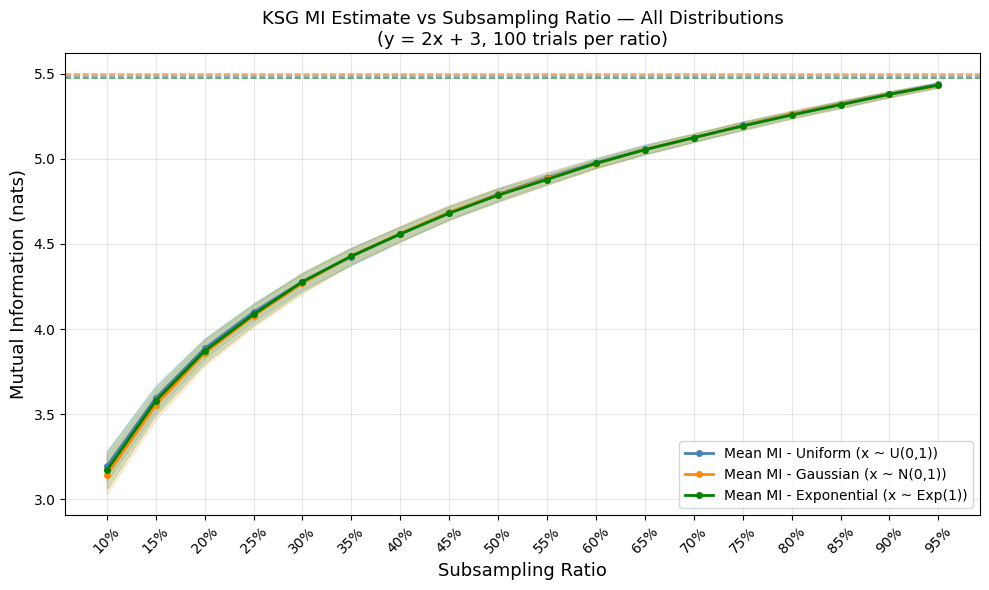

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

datasets = [
    (summary, mi_ceiling, "steelblue", "Uniform (x ~ U(0,1))"),
    (summary_g, mi_ceiling_g, "darkorange", "Gaussian (x ~ N(0,1))"),
    (summary_e, mi_ceiling_e, "green", "Exponential (x ~ Exp(1))"),
]

for summ, ceiling, color, label in datasets:
    ax.plot(summ["ratio"], summ["mean_mi"], color=color, linewidth=2, marker="o", markersize=4, label=f"Mean MI - {label}")
    ax.fill_between(summ["ratio"], summ["mean_mi"] - summ["std_mi"], summ["mean_mi"] + summ["std_mi"], alpha=0.15, color=color)
    ax.axhline(y=ceiling, color=color, linestyle="--", linewidth=1.2, alpha=0.7)

ax.set_xlabel("Subsampling Ratio", fontsize=13)
ax.set_ylabel("Mutual Information (nats)", fontsize=13)
ax.set_title("KSG MI Estimate vs Subsampling Ratio — All Distributions\n(y = 2x + 3, 100 trials per ratio)", fontsize=13)
ax.set_xticks(summary["ratio"])
ax.set_xticklabels([f"{int(r*100)}%" for r in summary["ratio"]], rotation=45)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("subsampling_overlay.png", dpi=150)
plt.show()

------------------

# Findings: KSG MI Subsampling Analysis

## Setup
We tested how the KSG mutual information estimator behaves when we subsample
datasets of varying sizes. For each experiment, we generated data using the
linear relationship y = 2x + 3, where x was drawn from three different
distributions: Uniform(0,1), meaning x is uniformly distributed between 0
and 1, Gaussian(0,1), meaning x follows a normal distribution with mean 0
and standard deviation 1, and Exponential(1), meaning x follows an
exponential distribution with a mean of 1 (scale parameter = 1), where all
values are positive and skewed to the right. We ran 100 trials per subsampling
ratio, ranging from 10% to 95% in steps of 5%. In each trial, we generated a
fresh random dataset of 1000 points and applied a random boolean index to
select the subsample. We computed the ceiling MI once on a single full
1000-point dataset for each distribution and used it as a reference.

## Finding 1: MI increases consistently with subsampling ratio
Across all three distributions, the mean MI estimate rose steadily as we
increased the subsampling ratio. At 10%, the mean MI hovered around 3.14 nats.
By 95%, it climbed to approximately 5.43 nats, approaching the ceiling closely.
This confirms that the KSG estimator captures more information as it sees more
data points, which is the expected behavior.

## Finding 2: Standard Deviation decreases as sample size grows
The standard deviation of MI estimates narrowed consistently as the ratio
increased. At 10%, the std was around 0.10 nats across all distributions. By
95%, it dropped to roughly 0.015 nats. This means that with more data, the
estimator not only gets closer to the true MI but also becomes more stable and
reliable across repeated trials.

## Finding 3: The curve flattens at higher ratios
The MI curve grew rapidly between 10% and 40%, then started flattening out
beyond 60-70%. This suggests diminishing returns, adding more data beyond a
certain threshold improves the estimate only marginally. This is an important
practical insight: we may not need the full dataset to get a reliable MI
estimate.

## Finding 4: The KSG estimator is robust across distributions
The most striking result came from the overlay plot. All three distributions
produced nearly identical MI curves across all subsampling ratios. The Uniform,
Gaussian, and Exponential experiments followed the same trajectory, with curves
that were almost indistinguishable from one another. This suggests that the KSG
estimator's subsampling behavior depends primarily on sample size rather than
the shape of the input distribution, at least when the underlying relationship
is a deterministic linear function.

## Finding 5: Ceiling values were consistent across distributions
The ceiling MI values were very close across all three distributions: Uniform
(5.4898 nats), Exponential (5.4731 nats), and Gaussian (5.5175 nats). The small
differences reflect the different differential entropies of each distribution
rather than any difference in correlation structure. It is worth noting that
each ceiling was computed once on a single fixed dataset, so slight run-to-run
variation is expected.

## Summary
The KSG estimator behaves predictably and robustly under subsampling. It
requires a reasonable sample size to produce stable and accurate MI estimates,
with the sharpest gains occurring between 10% and 50% of the data. Beyond 70%,
the estimates stabilize and converge toward the ceiling. Importantly, the choice
of input distribution had virtually no effect on the subsampling behavior,
suggesting that these findings generalize beyond the specific distributions we
tested.

Note: Since I didn't use a seed, the numbers written for analysis may differ with different runs, although the patterns won't change.